# CitizenTech é estimativa de monóxido de carbono no ar

**Machine Learning & Modelling é Global Solution 2026.2**  
**Integrantes:** João Pedro Morangoni (RM 570073) e João Vitor Xavier de Carvalho (RM 570633).

Objetivo: estimar a concentração horária de CO (mg/m³) a partir de sensores e variáveis meteorológicas do mesmo horário. Equipes municipais e moradores poderiam consultar estimativas para apoiar o acompanhamento ambiental. O projeto CitizenTech monitora bueiros; esta análise é um módulo ambiental complementar, não mede condições dentro de bueiros e não prevê enchentes. O alinhamento com o público e problema integrador deve ser confirmado pelo grupo. A estimativa não substitui instrumentos certificados ou decisão sanitária.

Fonte: [UCI Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality), Vito (2008), DOI 10.24432/C59K5F. Leituras horárias de uma estação na Itália em 2004–2005; resultados não são automaticamente transferíveis a outras cidades ou sensores. ODS 11 (cidades sustentáveis) e 3 (saúde e bem-estar).

## 1. Bibliotecas e carregamento

Instale as dependências de `IA/requirements.txt` e execute todas as células. O arquivo original usa ponto e vírgula como separador, vírgula decimal e `-200` para ausência. Os registros e resultados são exibidos no notebook, sem exportar dados.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

candidatos = [Path('IA/dataset/AirQualityUCI.csv'), Path('../dataset/AirQualityUCI.csv'), Path('dataset/AirQualityUCI.csv')]
caminho = next((p for p in candidatos if p.is_file()), None)
if caminho is None:
    raise FileNotFoundError('Não foi encontrado IA/dataset/AirQualityUCI.csv. Execute na raiz, em IA ou em IA/Machine_learning.')
bruto = pd.read_csv(caminho, sep=';', decimal=',', na_values=[-200])
print('Dimensões originais:', bruto.shape)
display(bruto.head(10))

Dimensões originais: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN
5,10/03/2004,23.00.00,1.2,1197.0,38.0,4.7,750.0,89.0,1337.0,96.0,1393.0,949.0,11.2,59.2,0.7848,NaN,NaN
6,11/03/2004,00.00.00,1.2,1185.0,31.0,3.6,690.0,62.0,1462.0,77.0,1333.0,733.0,11.3,56.8,0.7603,NaN,NaN
7,11/03/2004,01.00.00,1.0,1136.0,31.0,3.3,672.0,62.0,1453.0,76.0,1333.0,730.0,10.7,60.0,0.7702,NaN,NaN
8,11/03/2004,02.00.00,0.9,1094.0,24.0,2.3,609.0,45.0,1579.0,60.0,1276.0,620.0,10.7,59.7,0.7648,NaN,NaN
9,11/03/2004,03.00.00,0.6,1010.0,19.0,1.7,561.0,NaN,1705.0,NaN,1235.0,501.0,10.3,60.2,0.7517,NaN,NaN


## 2. Entendimento e qualidade dos dados

`CO(GT)` é a referência que queremos estimar. As entradas são as respostas de cinco sensores PT08 e temperatura (T), umidade relativa (RH) e absoluta (AH). As demais concentrações de referência são excluídas para evitar depender de outros analisadores de laboratório. Registros inteiramente vazios e colunas vazias são descartados; sem alvo não há como supervisionar o treinamento.

In [2]:
dados = bruto.dropna(how='all').dropna(axis=1, how='all').copy()
dados['data_hora'] = pd.to_datetime(dados['Date'] + ' ' + dados['Time'], format='%d/%m/%Y %H.%M.%S', errors='coerce')
entradas = ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
alvo = 'CO(GT)'
print('Registros com conteúdo:', len(dados), '| Datas inválidas:', dados.data_hora.isna().sum())
print('Período:', dados.data_hora.min(), 'até', dados.data_hora.max())
display(pd.DataFrame({'ausentes': dados[entradas + [alvo]].isna().sum(), 'percentual': (100*dados[entradas + [alvo]].isna().mean()).round(2)}))
display(dados[entradas + [alvo]].describe().T)
display(dados.head(10))

Registros com conteúdo: 9357 | Datas inválidas: 0
Período: 2004-03-10 18:00:00 até 2005-04-04 14:00:00


,ausentes,percentual
PT08.S1(CO),366,3.91
PT08.S2(NMHC),366,3.91
PT08.S3(NOx),366,3.91
PT08.S4(NO2),366,3.91
PT08.S5(O3),366,3.91
T,366,3.91
RH,366,3.91
AH,366,3.91
CO(GT),1683,17.99


,count,mean,std,min,25%,50%,75%,max
PT08.S1(CO),8991.0,1099.833166,217.080037,647.0000,937.0000,1063.0000,1231.0000,2040.000
PT08.S2(NMHC),8991.0,939.153376,266.831429,383.0000,734.5000,909.0000,1116.0000,2214.000
PT08.S3(NOx),8991.0,835.493605,256.817320,322.0000,658.0000,806.0000,969.5000,2683.000
PT08.S4(NO2),8991.0,1456.264598,346.206794,551.0000,1227.0000,1463.0000,1674.0000,2775.000
PT08.S5(O3),8991.0,1022.906128,398.484288,221.0000,731.5000,963.0000,1273.5000,2523.000
T,8991.0,18.317829,8.832116,-1.9000,11.8000,17.8000,24.4000,44.600
RH,8991.0,49.234201,17.316892,9.2000,35.8000,49.6000,62.5000,88.700
AH,8991.0,1.025530,0.403813,0.1847,0.7368,0.9954,1.3137,2.231
CO(GT),7674.0,2.152750,1.453252,0.1000,1.1000,1.8000,2.9000,11.900


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,data_hora
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00
5,10/03/2004,23.00.00,1.2,1197.0,38.0,4.7,750.0,89.0,1337.0,96.0,1393.0,949.0,11.2,59.2,0.7848,2004-03-10 23:00:00
6,11/03/2004,00.00.00,1.2,1185.0,31.0,3.6,690.0,62.0,1462.0,77.0,1333.0,733.0,11.3,56.8,0.7603,2004-03-11 00:00:00
7,11/03/2004,01.00.00,1.0,1136.0,31.0,3.3,672.0,62.0,1453.0,76.0,1333.0,730.0,10.7,60.0,0.7702,2004-03-11 01:00:00
8,11/03/2004,02.00.00,0.9,1094.0,24.0,2.3,609.0,45.0,1579.0,60.0,1276.0,620.0,10.7,59.7,0.7648,2004-03-11 02:00:00
9,11/03/2004,03.00.00,0.6,1010.0,19.0,1.7,561.0,NaN,1705.0,NaN,1235.0,501.0,10.3,60.2,0.7517,2004-03-11 03:00:00


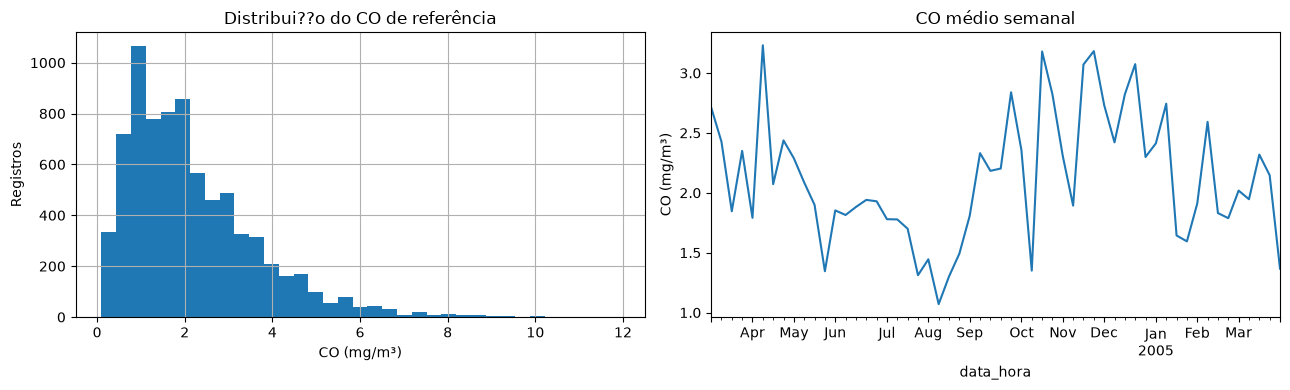

Correlação linear exploratória com CO:


,CO(GT)
CO(GT),1.000000
PT08.S2(NMHC),0.915514
PT08.S1(CO),0.879288
PT08.S5(O3),0.854182
PT08.S4(NO2),0.630703
RH,0.048890
AH,0.048556
T,0.022109
PT08.S3(NOx),-0.703446


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dados[alvo].dropna().hist(bins=35, ax=ax[0]); ax[0].set(title='Distribuição do CO de referência', xlabel='CO (mg/m³)', ylabel='Registros')
dados.set_index('data_hora')[alvo].resample('7D').mean().plot(ax=ax[1], title='CO médio semanal'); ax[1].set_ylabel('CO (mg/m³)')
plt.tight_layout(); plt.show()
print('Correlação linear exploratória com CO:')
display(dados[entradas + [alvo]].corr()[[alvo]].sort_values(alvo, ascending=False))

## 3. Preparação e divisão temporal

Eliminamos linhas sem data, sem referência de CO ou sem qualquer entrada. Ordenamos cronologicamente: primeiros 80% para desenvolvimento e últimos 20% para teste. A mediana e a padronização são aprendidas apenas no treino em cada divisão do pipeline, evitando vazamento. `TimeSeriesSplit` usa passado para validar dados posteriores; a separação temporal é mais realista que embaralhar uma série. O alvo é do mesmo instante, portanto não é uma previsão futura.

In [4]:
base = dados.dropna(subset=['data_hora', alvo]).dropna(subset=entradas, how='all').sort_values('data_hora').reset_index(drop=True)
print('Linhas utilizáveis:', len(base), '| Removidas:', len(dados)-len(base))
corte = int(len(base)*0.8)
treino, teste = base.iloc[:corte], base.iloc[corte:]
X_train, y_train = treino[entradas], treino[alvo]
X_test, y_test = teste[entradas], teste[alvo]
print('Treino:', len(treino), treino.data_hora.min(), 'até', treino.data_hora.max())
print('Teste:', len(teste), teste.data_hora.min(), 'até', teste.data_hora.max())

Linhas utilizáveis: 7344 | Removidas: 2013
Treino: 5875 2004-03-10 18:00:00 até 2005-01-28 11:00:00
Teste: 1469 2005-01-28 12:00:00 até 2005-04-04 14:00:00


## 4. Modelagem e ajuste

Baseline: média do treino. Ridge é um modelo linear regularizado e interpretável, com padronização. Random Forest capta relações não lineares e interações; não precisa de escala. Selecionamos hiperparâmetros da floresta por menor MAE médio em três divisões temporais, usando somente desenvolvimento. A comparação final com Ridge e baseline usa o mesmo conjunto de teste.

In [5]:
baseline = DummyRegressor(strategy='mean')
ridge = Pipeline([('imputacao', SimpleImputer(strategy='median')), ('escala', StandardScaler()), ('modelo', Ridge(alpha=1.0))])
floresta = Pipeline([('imputacao', SimpleImputer(strategy='median')), ('modelo', RandomForestRegressor(random_state=42, n_jobs=-1))])
busca = GridSearchCV(floresta, {'modelo__n_estimators': [80], 'modelo__max_depth': [6, 12], 'modelo__min_samples_leaf': [2, 8]}, scoring='neg_mean_absolute_error', cv=TimeSeriesSplit(n_splits=3), n_jobs=1, return_train_score=True)
baseline.fit(X_train, y_train); ridge.fit(X_train, y_train); busca.fit(X_train, y_train)
print('Melhores parâmetros:', busca.best_params_, '| MAE temporal de validação:', round(-busca.best_score_, 3))
display(pd.DataFrame(busca.cv_results_)[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False))

Melhores parâmetros: {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 80} | MAE temporal de validação: 0.328


,params,mean_train_score,mean_test_score,std_test_score
2,"{'modelo__max_depth': 12, 'modelo__min_samples...",-0.101006,-0.328112,0.103153
3,"{'modelo__max_depth': 12, 'modelo__min_samples...",-0.156179,-0.328654,0.105001
0,"{'modelo__max_depth': 6, 'modelo__min_samples_...",-0.185893,-0.335353,0.105362
1,"{'modelo__max_depth': 6, 'modelo__min_samples_...",-0.190939,-0.335603,0.107960


## 5. Avaliação e generalização

MAE e RMSE são erros em mg/m³ (menores são melhores); RMSE penaliza mais erros grandes. R² compara a variância explicada com a média do próprio conjunto (mais próximo de 1 é melhor; pode ser negativo). A diferença entre treino e teste ajuda a investigar sobreajuste, mas a mudança temporal da distribuição também pode contribuir. A escolha usa MAE no teste para esta comparação acadêmica; para implantação, seria necessário outro período independente após a seleção.

,Modelo,Particao,MAE,RMSE,R²
0,Baseline,Treino,1.128,1.465,0.000
1,Baseline,Teste,1.068,1.320,-0.030
2,Ridge,Treino,0.322,0.485,0.891
3,Ridge,Teste,0.344,0.484,0.862
4,Random Forest ajustada,Treino,0.144,0.219,0.978
5,Random Forest ajustada,Teste,0.355,0.519,0.841


Modelo final pelo MAE de teste: Ridge
Diferença MAE teste - treino:


Modelo
Baseline                 -0.060
Random Forest ajustada    0.211
Ridge                     0.022
dtype: float64

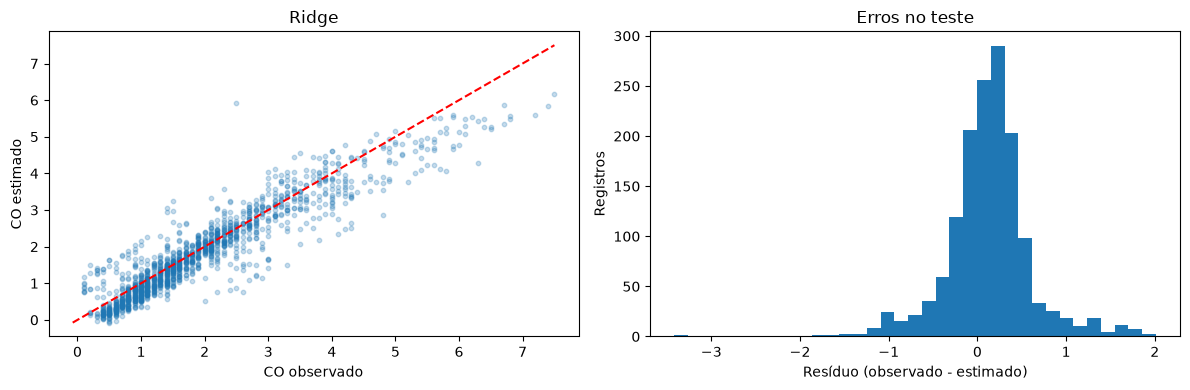

In [6]:
modelos = {'Baseline': baseline, 'Ridge': ridge, 'Random Forest ajustada': busca.best_estimator_}
def metricas(y, pred):
    return {'MAE': mean_absolute_error(y, pred), 'RMSE': np.sqrt(mean_squared_error(y, pred)), 'R²': r2_score(y, pred)}
resultados = []
for nome, modelo in modelos.items():
    for particao, x, y in [('Treino', X_train, y_train), ('Teste', X_test, y_test)]:
        resultados.append({'Modelo': nome, 'Particao': particao, **metricas(y, modelo.predict(x))})
tabela = pd.DataFrame(resultados)
display(tabela.round(3))
melhor_nome = tabela.query("Particao == 'Teste' and Modelo != 'Baseline'").sort_values('MAE').iloc[0]['Modelo']
modelo_final = modelos[melhor_nome]
print('Modelo final pelo MAE de teste:', melhor_nome)
print('Diferença MAE teste - treino:')
display((tabela.pivot(index='Modelo', columns='Particao', values='MAE').eval('Teste - Treino')).round(3))
pred = modelo_final.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y_test, pred, alpha=.25, s=10); lim = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]; ax[0].plot(lim, lim, 'r--'); ax[0].set(xlabel='CO observado', ylabel='CO estimado', title=melhor_nome)
ax[1].hist(y_test - pred, bins=35); ax[1].set(xlabel='Resíduo (observado - estimado)', ylabel='Registros', title='Erros no teste')
plt.tight_layout(); plt.show()

## 6. Interpretação das variáveis

A importância por permutação mede o aumento médio do MAE no teste quando uma variável é embaralhada. Não demonstra causalidade; sensores correlacionados podem compartilhar importância. Usa-se o teste apenas para interpretação descritiva, sem retreinar a partir desse resultado.

,Variável,Aumento médio do MAE,Desvio
1,PT08.S2(NMHC),1.109,0.013
0,PT08.S1(CO),0.141,0.004
2,PT08.S3(NOx),0.108,0.003
3,PT08.S4(NO2),0.058,0.001
5,T,0.045,0.001
4,PT08.S5(O3),0.015,0.001
7,AH,0.001,0.001
6,RH,0.000,0.000


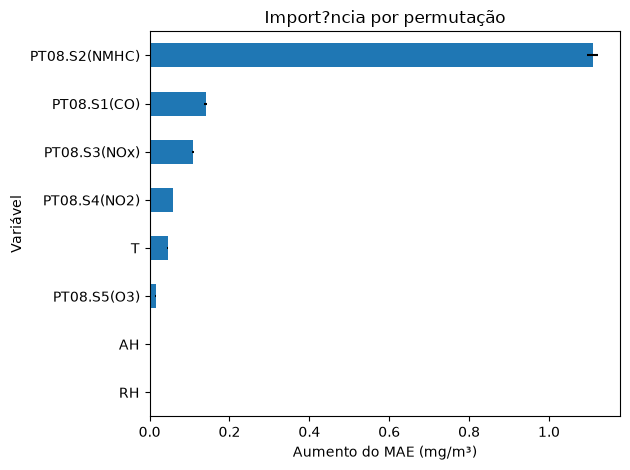

Variável com maior importância observada: PT08.S2(NMHC)


In [7]:
perm = permutation_importance(modelo_final, X_test, y_test, scoring='neg_mean_absolute_error', n_repeats=5, random_state=42, n_jobs=1)
importancias = pd.DataFrame({'Variável': entradas, 'Aumento médio do MAE': perm.importances_mean, 'Desvio': perm.importances_std}).sort_values('Aumento médio do MAE', ascending=False)
display(importancias.round(3))
importancias.sort_values('Aumento médio do MAE').plot.barh(x='Variável', y='Aumento médio do MAE', xerr='Desvio', legend=False, title='Importância por permutação'); plt.xlabel('Aumento do MAE (mg/m³)'); plt.tight_layout(); plt.show()
print('Variável com maior importância observada:', importancias.iloc[0]['Variável'])

## 7. Demonstração e aplicação

Amostras abaixo pertencem ao período de teste e não foram usadas para ajustar os modelos. Uma futura interface poderia mostrar valor estimado e horário para equipes e moradores, acompanhados da identificação de que se trata de estimativa. Não há integração com hardware ou backend implementada aqui; ausência de calibração local, deriva dos sensores, dados históricos de uma única cidade e falta de intervalos de confiança limitam o uso.

In [8]:
exemplos = teste.iloc[:10][['data_hora'] + entradas + [alvo]].copy()
exemplos['CO estimado (mg/m³)'] = modelo_final.predict(exemplos[entradas])
exemplos['Erro absoluto'] = (exemplos[alvo] - exemplos['CO estimado (mg/m³)']).abs()
display(exemplos.round(3))
print('Os registros, métricas e gráficos ficam no notebook; nenhum arquivo de dados é criado.')

C:\Users\Dell\AppData\Local\Temp\ipykernel_8668\485731531.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(exemplos.round(3))


,data_hora,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,CO(GT),CO estimado (mg/m³),Erro absoluto
5875,2005-01-28 12:00:00,970.0,798.0,842.0,941.0,874.0,4.5,49.6,0.421,1.8,1.568,0.232
5876,2005-01-28 13:00:00,943.0,781.0,871.0,925.0,722.0,4.4,48.4,0.409,1.4,1.482,0.082
5877,2005-01-28 14:00:00,994.0,871.0,793.0,997.0,836.0,4.7,47.2,0.408,2.1,1.913,0.187
5878,2005-01-28 15:00:00,932.0,767.0,888.0,920.0,669.0,4.2,49.5,0.412,1.6,1.418,0.182
5879,2005-01-28 16:00:00,891.0,706.0,949.0,860.0,600.0,3.4,50.7,0.399,1.3,1.137,0.163
5880,2005-01-29 02:00:00,793.0,480.0,1306.0,745.0,376.0,1.9,49.7,0.353,0.7,0.210,0.490
5881,2005-01-29 03:00:00,790.0,455.0,1376.0,751.0,336.0,1.6,52.9,0.369,0.6,0.145,0.455
5882,2005-01-29 04:00:00,776.0,445.0,1460.0,737.0,330.0,1.4,53.8,0.369,0.5,0.153,0.347
5883,2005-01-29 05:00:00,766.0,448.0,1494.0,734.0,321.0,1.0,54.7,0.366,0.5,0.191,0.309
5884,2005-01-29 06:00:00,774.0,458.0,1473.0,735.0,334.0,1.4,52.3,0.359,0.4,0.227,0.173


Os registros, métricas e gráficos ficam no notebook; nenhum arquivo de dados é criado.


## 8. Conclusão e entrega

Compare os erros de treino e teste acima: uma diferença positiva grande sugere possível sobreajuste ou mudança temporal; erros altos em ambos sugerem possível subajuste. A melhor escolha reportada é condicionada ao período de teste e não garante desempenho futuro. Antes de uso real, validar com dados atuais e locais, calibração dos sensores e testes independentes, inclusive para grupos e localidades diferentes.